## Import Library dan Image


Ukuran gambar: (957, 1280)


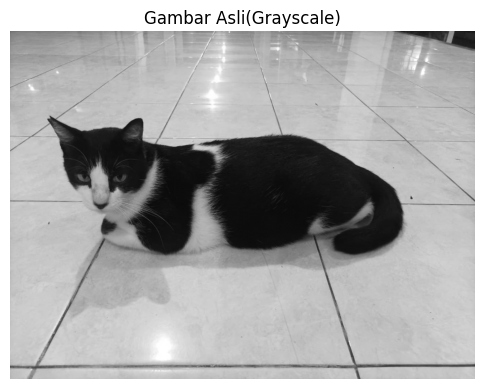

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open('Image/El_Gato.jpeg').convert('L')
img_array = np.array(img)

print("Ukuran gambar:", img_array.shape)
plt.figure(figsize=(6,6))
plt.imshow(img_array, cmap='gray')
plt.title('Gambar Asli(Grayscale)')
plt.axis('off')
plt.show()

## Auto Treshold using Otsu Methode

In [ ]:
def OtsuMethode(img_matrix):
    rows, cols = img_matrix.shape
    total_pixels = rows * cols
    histogram = np.zeros(256)
    for i in range(rows):
        for j in range(cols):
            val = img_matrix[i, j]
            histogram[val] += 1
    probabilities = histogram / total_pixels
    best_threshold = 0
    max_variance = 0
    for p in range(256):
        w_b = np.sum(probabilities[:p])
        w_f = np.sum(probabilities[p:])
        if w_b == 0 or w_f == 0:
            continue
        intensities_b = np.arange(p)
        intensities_f = np.arange(p, 256)
        mean_b = np.sum(probabilities[:p] * intensities_b)/w_b
        mean_f = np.sum(probabilities[p:] * intensities_f)/w_f
        variance = w_b * w_f * (mean_b - mean_f) **2
        if variance > max_variance:
            max_variance = variance
            best_threshold = p
    giprint(f"Nilai Threshold Optimal Otsu: {best_threshold}")
    binary_img = np.zeros((rows, cols), dtype=np.uint8)
    
    for i in range(rows):
        for j in range(cols):
            if img_matrix[i, j] <= best_threshold:
                binary_img[i, j] = 255
            else:
                binary_img[i, j] = 0
                
    return binary_img, best_threshold

otsu_segmented_img, optimal_t = OtsuMethode(img_array)

        
        

Nilai Threshold Optimal Otsu: 1
Nilai Threshold Optimal Otsu: 2
Nilai Threshold Optimal Otsu: 3
Nilai Threshold Optimal Otsu: 4
Nilai Threshold Optimal Otsu: 5
Nilai Threshold Optimal Otsu: 6
Nilai Threshold Optimal Otsu: 7
Nilai Threshold Optimal Otsu: 8
Nilai Threshold Optimal Otsu: 9
Nilai Threshold Optimal Otsu: 10
Nilai Threshold Optimal Otsu: 11
Nilai Threshold Optimal Otsu: 12
Nilai Threshold Optimal Otsu: 13
Nilai Threshold Optimal Otsu: 14
Nilai Threshold Optimal Otsu: 15
Nilai Threshold Optimal Otsu: 16
Nilai Threshold Optimal Otsu: 17
Nilai Threshold Optimal Otsu: 18
Nilai Threshold Optimal Otsu: 19
Nilai Threshold Optimal Otsu: 20
Nilai Threshold Optimal Otsu: 21
Nilai Threshold Optimal Otsu: 22
Nilai Threshold Optimal Otsu: 23
Nilai Threshold Optimal Otsu: 24
Nilai Threshold Optimal Otsu: 25
Nilai Threshold Optimal Otsu: 26
Nilai Threshold Optimal Otsu: 27
Nilai Threshold Optimal Otsu: 28
Nilai Threshold Optimal Otsu: 29
Nilai Threshold Optimal Otsu: 30
Nilai Threshold Opt

## Hasil Image Segmentation Menggunakan Otsu Methode

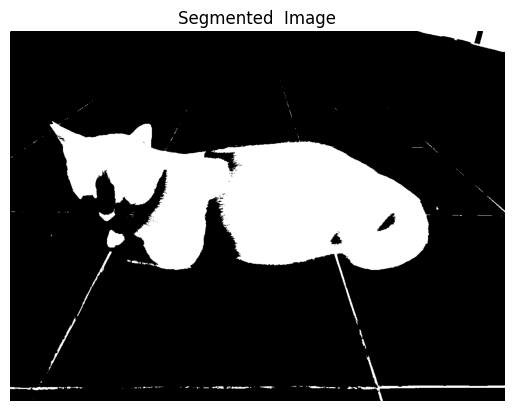

In [12]:
plt.imshow(otsu_segmented_img, cmap='gray')
plt.title('Segmented  Image')
plt.axis('off')
plt.show()

## Morphological Processing Implementation

### Errotion Function

In [23]:
def Errotion(binary_img, kernel_size=3):
    rows, cols = binary_img.shape
    pad = kernel_size // 2
    eroded_img = np.zeros((rows, cols), dtype=np.uint8)
    padded_img = np.pad(binary_img, pad, mode='constant', constant_values=0)
    
    for i in range(rows):
        for j in range(cols):
            region = padded_img[i : i + kernel_size, j : j + kernel_size]
            if np.min(region) == 255:
                eroded_img[i, j] = 255
            else:
                eroded_img[i, j] = 0
                
    return eroded_img



### Dilation Function

In [22]:
def Dilation(binary_img, kernel_size=3):
    rows, cols = binary_img.shape
    pad = kernel_size // 2
    dilated_img = np.zeros((rows, cols), dtype=np.uint8)
    padded_img = np.pad(binary_img, pad, mode='constant', constant_values=0)
    
    for i in range(rows):
        for j in range(cols):                
            region = padded_img[i : i + kernel_size, j : j + kernel_size]
            if np.max(region) == 255:
                dilated_img[i, j] = 255
            else:
                dilated_img[i, j] = 0
                
    return dilated_img

### Opening to remove the segmented line (errotion + dilation)

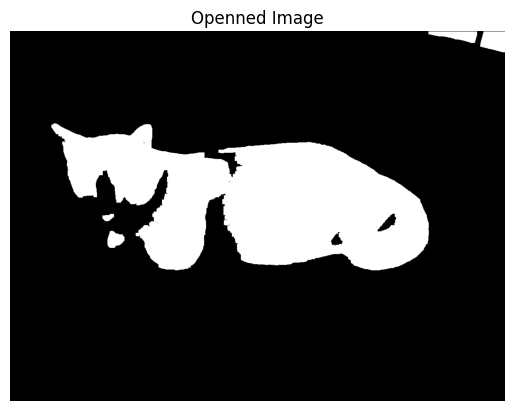

In [28]:
img_erroded = Errotion(otsu_segmented_img, kernel_size= 8)
img_openned = Dilation(img_erroded, kernel_size=8)
plt.imshow(img_openned, cmap='gray')
plt.title('Openned Image')
plt.axis('off')
plt.show()

### Closing Image (Dilation + errotion)

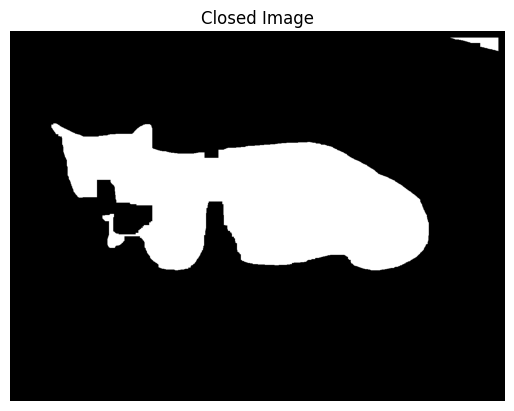

In [40]:
img_dilated = Dilation(img_openned, kernel_size=35)
img_closed = Errotion(img_dilated, kernel_size=35)
plt.imshow(img_closed, cmap='gray')
plt.title('Closed Image')
plt.axis('off')
plt.show()